# Exercise 2 · ML model — predicting employee attrition

**Question:** Can a model predict who will leave?

We train a **Random Forest** (black box, explained with XAI in the next step) and compare it with **logistic regression** (simple benchmark).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay, accuracy_score,
                             average_precision_score, f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, TunedThresholdClassifierCV, cross_validate,
                                     train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", context="notebook")
SEED = 42

## 1 Data preparation
Same cleaning as in the EDA. Text columns are turned into numbers:
- `OverTime`, `Gender` → 0/1 (`Gender`: 1 = male)
- `BusinessTravel` → 0/1/2 (none, rarely, frequently)
- `Department`, `EducationField`, `JobRole`, `MaritalStatus` → one column per category

Nothing else is needed.

In [3]:
df = pd.read_csv("WA_Fn-UseC_-HR-Employee-Attrition.csv").drop(
    columns=["EmployeeCount", "StandardHours", "Over18", "EmployeeNumber"])
y = (df.pop("Attrition") == "Yes").astype(int)
df["OverTime"] = (df["OverTime"] == "Yes").astype(int)
df["Gender"] = (df["Gender"] == "Male").astype(int)
df["BusinessTravel"] = df["BusinessTravel"].map({"Non-Travel": 0, "Travel_Rarely": 1, "Travel_Frequently": 2})
X = pd.get_dummies(df, dtype=int)
print(f"{X.shape[0]} employees, {X.shape[1]} model columns (from 30 features), attrition rate {y.mean():.1%}")

1470 employees, 47 model columns (from 30 features), attrition rate 16.1%


## 2 Train-test split
80 % of employees to train, 20 % to test. Both parts keep the 16 % attrition rate. The test set is used only once, at the end.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"train: {len(y_train)} employees, {y_train.sum()} leavers | test: {len(y_test)} employees, {y_test.sum()} leavers")

train: 1176 employees, 190 leavers | test: 294 employees, 47 leavers


## 3 Models & settings
Leavers are rare, so both models give them extra weight (`class_weight="balanced"`).

- **Logistic regression:** default settings.
- **Random Forest:** 300 trees. We try 36 combinations of settings and keep the best one (tested with 5-fold cross-validation on the training data).

In [4]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
lr = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))
grid = GridSearchCV(
    RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
    {"max_depth": [None, 6, 10], "min_samples_leaf": [1, 3, 5, 10], "max_features": ["sqrt", 0.3, 0.5]},
    scoring="roc_auc", cv=cv,
).fit(X_train, y_train)
rf = grid.best_estimator_
print("best Random Forest settings:", grid.best_params_)
res = pd.DataFrame(grid.cv_results_)
print(f"ROC-AUC across the grid: {res['mean_test_score'].min():.3f} – {res['mean_test_score'].max():.3f}")

best Random Forest settings: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 3}
ROC-AUC across the grid: 0.788 – 0.813


### Comparison on the training data
- **ROC-AUC:** how well the model ranks leavers above stayers. 0.5 = guessing, 1.0 = perfect.
- **Avg precision:** same idea, focused on the leavers. Guessing gives 0.16.

In [5]:
models = {"Logistic regression": lr, "Random Forest": rf}
cv_table = pd.DataFrame({
    name: {f"{s} {stat}": getattr(r[f"test_{k}"], stat)()
           for k, s in [("roc_auc", "ROC-AUC"), ("average_precision", "Avg precision")] for stat in ("mean", "std")}
    for name, m in models.items()
    for r in [cross_validate(m, X_train, y_train, cv=cv, scoring=["roc_auc", "average_precision"])]
}).T.round(3)
cv_table

,ROC-AUC mean,ROC-AUC std,Avg precision mean,Avg precision std
Logistic regression,0.824,0.035,0.604,0.095
Random Forest,0.813,0.028,0.563,0.067


## 4 Cut-off (threshold)
The model gives each employee a probability of leaving. Everyone above the cut-off is flagged as "will leave".
0.5 is only a habit, so we pick the cut-off that works best on the training data.

In [6]:
tuned = {name: TunedThresholdClassifierCV(m, scoring="f1", cv=cv).fit(X_train, y_train) for name, m in models.items()}
for name, t in tuned.items():
    print(f"{name}: tuned threshold = {t.best_threshold_:.2f}")

Logistic regression: tuned threshold = 0.76
Random Forest: tuned threshold = 0.44


## 5 Results on the test set
- **Recall:** share of real leavers the model caught.
- **Precision:** share of flagged employees who really left.
- **F1:** one number combining recall and precision.
- **Accuracy:** share of all predictions that are right.

In [7]:
def evaluate(proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {"threshold": threshold, "ROC-AUC": roc_auc_score(y_test, proba),
            "Avg precision": average_precision_score(y_test, proba),
            "Recall (leavers)": recall_score(y_test, pred), "Precision (leavers)": precision_score(y_test, pred, zero_division=0),
            "F1 (leavers)": f1_score(y_test, pred), "Accuracy": accuracy_score(y_test, pred)}


proba = {name: t.estimator_.predict_proba(X_test)[:, 1] for name, t in tuned.items()}
rows = {"Baseline: everyone stays": evaluate(pd.Series(0.0, index=y_test.index), 0.5)}
for name, t in tuned.items():
    rows[f"{name} @ 0.50"] = evaluate(proba[name], 0.5)
    rows[f"{name} @ tuned"] = evaluate(proba[name], t.best_threshold_)
results = pd.DataFrame(rows).T.round(3)
results

,threshold,ROC-AUC,Avg precision,Recall (leavers),Precision (leavers),F1 (leavers),Accuracy
Baseline: everyone stays,0.500,0.500,0.160,0.000,0.000,0.000,0.840
Logistic regression @ 0.50,0.500,0.799,0.541,0.638,0.357,0.458,0.759
Logistic regression @ tuned,0.763,0.799,0.541,0.383,0.581,0.462,0.857
Random Forest @ 0.50,0.500,0.787,0.416,0.447,0.477,0.462,0.833
Random Forest @ tuned,0.440,0.787,0.416,0.553,0.419,0.477,0.806


**Reading the curves.** Each curve shows the trade-off for every possible cut-off.
- **ROC curve (left):** leavers caught (up) against false alarms (right). Closer to the top-left corner = better. The diagonal = guessing.
- **Precision-recall curve (right):** higher = better. The dashed line = guessing (16 %).

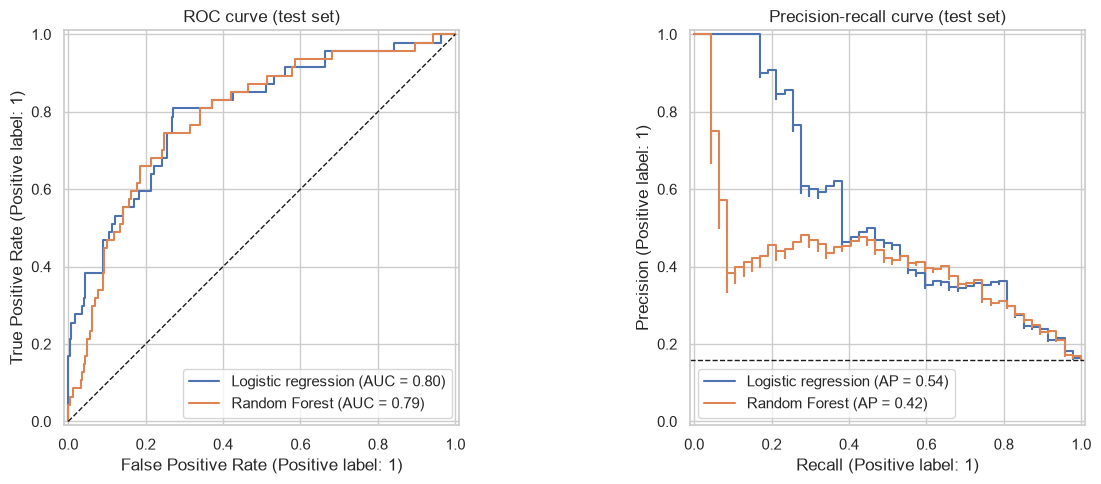

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name in models:
    RocCurveDisplay.from_predictions(y_test, proba[name], name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, proba[name], name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set_title("ROC curve (test set)")
axes[1].axhline(y_test.mean(), ls="--", c="k", lw=1)
axes[1].set_title("Precision-recall curve (test set)")
fig.tight_layout()

**Reading the confusion matrix.** Rows = what really happened, columns = what the model predicted.
Bottom-right = leavers caught, bottom-left = leavers missed, top-right = false alarms.

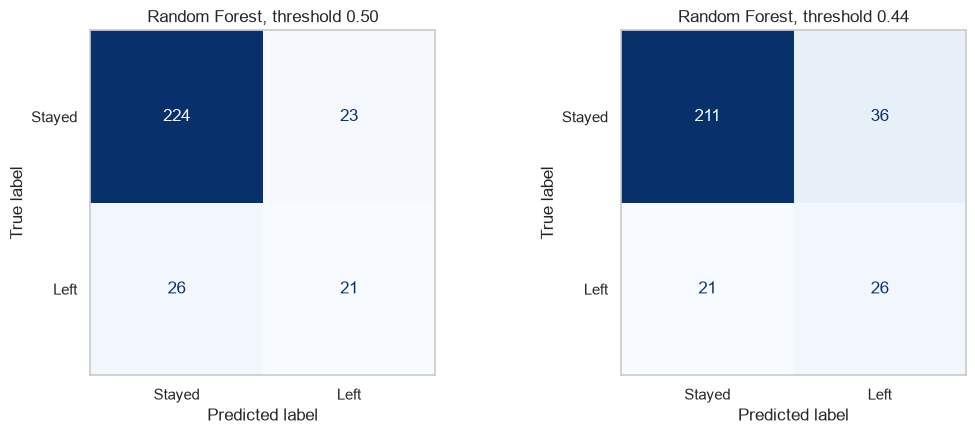

In [9]:
thr = tuned["Random Forest"].best_threshold_
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, t in zip(axes, [0.5, thr]):
    ConfusionMatrixDisplay.from_predictions(y_test, (proba["Random Forest"] >= t).astype(int),
                                            display_labels=["Stayed", "Left"], cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"Random Forest, threshold {t:.2f}")
    ax.grid(False)
fig.tight_layout()

## 6 Takeaways

**Can we predict attrition? Partly. Good for a risk ranking, not for a sure yes/no per person.**

- **Ranking:** ROC-AUC 0.79. A leaver gets a higher risk score than a stayer about 4 times out of 5.
- **As a warning list** (cut-off 0.44): 62 of 294 employees are flagged and 26 of them really left. That is a 42 % hit rate, against 16 % by chance. 26 of 47 leavers are caught, 21 are missed.
- **Accuracy misleads:** "everyone stays" is 84 % accurate but finds no leaver.
- **The cut-off is a business choice:** a lower cut-off catches more leavers but raises more false alarms.
- **Benchmark:** logistic regression does about as well (ROC-AUC 0.80). We still explain the Random Forest, because the PoC is about opening up a black box.
- **Settings matter little:** ROC-AUC stays between 0.79 and 0.81 for all settings we tried.

**Limits.** The test set has only 47 leavers, so the numbers are rough. The data is one snapshot: it shows who left, not when.